In [7]:

import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()


Saving Dataset.csv to Dataset (1).csv


In [8]:

# TASK 1: NETFLIX DATA CLEANING

# Load the dataset
df = pd.read_csv('Dataset.csv')

# Display first 5 records
print("FIRST 5 RECORDS")
display(df.head())

# Display dataset shape
print("\nDATASET SHAPE")
print(df.shape)

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION")
df.info()


FIRST 5 RECORDS


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



DATASET SHAPE
(8790, 10)

COLUMN NAMES
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [9]:

# CHECK MISSING VALUES

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values in Each Column:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Total Missing Values:
0


In [10]:

# STEP 3: CHECK AND REMOVE DUPLICATES

# Check duplicate records
print("Total Duplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Check duplicates after removal
print("\nDuplicates After Cleaning:")
print(df.duplicated().sum())

# Display updated dataset shape
print("\nUpdated Dataset Shape:")
print(df.shape)


Total Duplicate Records:
0

Duplicates After Cleaning:
0

Updated Dataset Shape:
(8790, 10)


In [11]:

# STEP 4: STANDARDIZE COLUMNS

# Remove unwanted spaces from Country values
df['country'] = df['country'].apply(
    lambda x: ', '.join(country.strip() for country in x.split(','))
    if isinstance(x, str) else x
)

# Standardize Rating values
df['rating'] = df['rating'].str.strip().str.upper()

# Standardize Type values
df['type'] = df['type'].str.strip().str.title()

# Display standardized columns
print("STANDARDIZED COUNTRY:")
print(df['country'].head())

print("\nSTANDARDIZED RATING:")
print(df['rating'].head())

print("\nSTANDARDIZED TYPE:")
print(df['type'].head())

print("\nSTANDARDIZATION COMPLETED!")


STANDARDIZED COUNTRY:
0    United States
1           France
2    United States
3           Brazil
4    United States
Name: country, dtype: object

STANDARDIZED RATING:
0    PG-13
1    TV-MA
2    TV-MA
3    TV-PG
4    TV-MA
Name: rating, dtype: object

STANDARDIZED TYPE:
0      Movie
1    Tv Show
2    Tv Show
3      Movie
4      Movie
Name: type, dtype: object

STANDARDIZATION COMPLETED!


In [12]:

# Correct Type column formatting

df['type'] = df['type'].replace({
    'Tv Show': 'TV Show',
    'Movie': 'Movie'
})

print("Corrected Content Types:")
print(df['type'].value_counts())

print("\nFinal Type Values:")
print(df['type'].unique())



Corrected Content Types:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Final Type Values:
['Movie' 'TV Show']


In [13]:

# Export cleaned Netflix dataset

df.to_csv('Netflix_Cleaned_Data.csv', index=False)

print("Netflix dataset cleaned successfully!")
print("File exported: Netflix_Cleaned_Data.csv")

# Download the cleaned dataset
from google.colab import files
files.download('Netflix_Cleaned_Data.csv')


Netflix dataset cleaned successfully!
File exported: Netflix_Cleaned_Data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

# TASK 2: CONTENT TYPE ANALYSIS DASHBOARD

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv('Netflix_Cleaned_Data.csv')

print("Dataset Loaded Successfully!")

# Display first 5 records
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)


Dataset Loaded Successfully!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Dataset Shape: (8790, 10)


In [15]:

# STEP 2: CONTENT TYPE DISTRIBUTION

content_counts = df['type'].value_counts()

print("NETFLIX CONTENT TYPE DISTRIBUTION")
print("---------------------------------")

print("Movies:", content_counts['Movie'])
print("TV Shows:", content_counts['TV Show'])
print("Total Content:", content_counts.sum())

# Calculate content percentages
percentages = df['type'].value_counts(normalize=True) * 100

print("\nCONTENT PERCENTAGES")
print(percentages.round(2))


NETFLIX CONTENT TYPE DISTRIBUTION
---------------------------------
Movies: 6126
TV Shows: 2664
Total Content: 8790

CONTENT PERCENTAGES
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


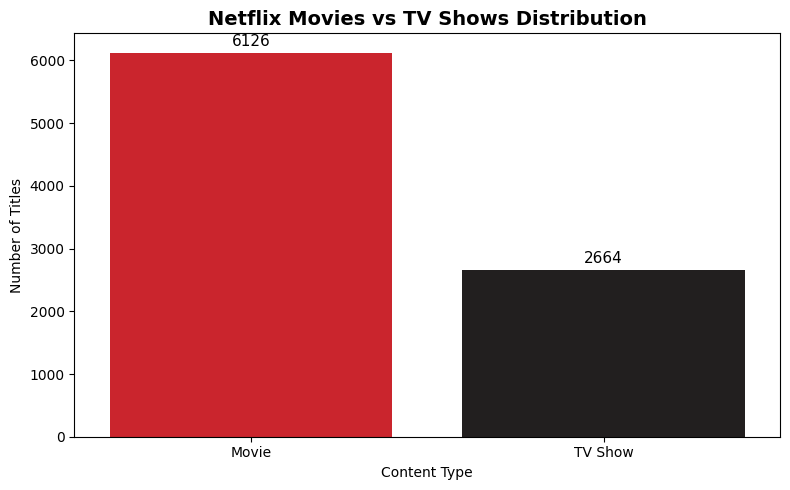

In [16]:

# STEP 3: BAR CHART - CONTENT DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    hue=content_counts.index,
    palette=['#E50914', '#221F1F'],
    legend=False
)

plt.title('Netflix Movies vs TV Shows Distribution',
          fontsize=14, fontweight='bold')

plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

# Display values above bars
for i, value in enumerate(content_counts.values):
    plt.text(i, value + 100, str(value),
             ha='center', fontsize=11)

plt.tight_layout()
plt.savefig('Netflix_Bar_Chart.png', dpi=300)
plt.show()


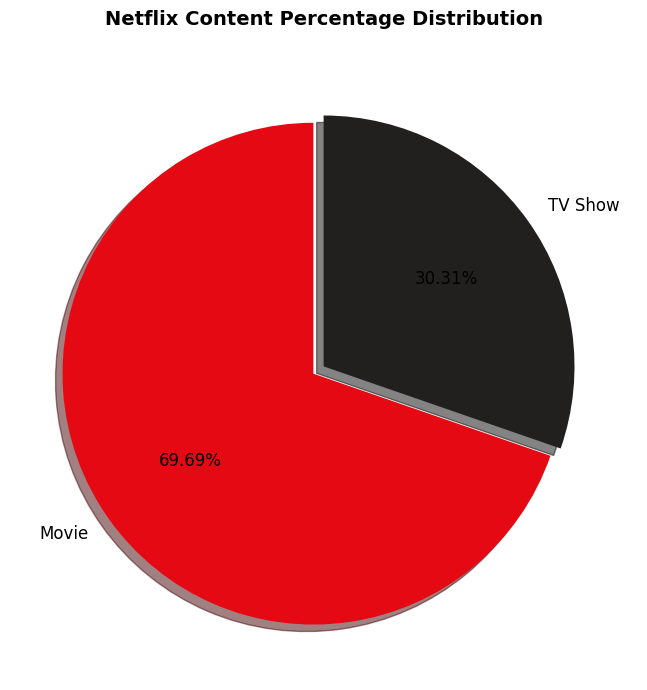

In [17]:

# STEP 4: PIE CHART - CONTENT PERCENTAGE

plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    colors=['#E50914', '#221F1F'],
    explode=(0.05, 0),
    shadow=True,
    textprops={'fontsize': 12}
)

plt.title(
    'Netflix Content Percentage Distribution',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()

plt.savefig(
    'Netflix_Pie_Chart.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



In [18]:

# STEP 5: BUSINESS INSIGHTS AND SUMMARY

movie_count = content_counts['Movie']
tv_count = content_counts['TV Show']

movie_percentage = (movie_count / len(df)) * 100
tv_percentage = (tv_count / len(df)) * 100

print("NETFLIX CONTENT ANALYSIS REPORT")
print("================================")

print(f"Total Netflix Content: {len(df)}")

print(f"\nTotal Movies: {movie_count}")
print(f"Total TV Shows: {tv_count}")

print("\nKEY BUSINESS INSIGHTS")
print("----------------------")

print(f"1. Movies account for {movie_percentage:.2f}% of total content.")

print(f"2. TV Shows account for {tv_percentage:.2f}% of total content.")

print("3. Movies are the dominant content type on Netflix.")

print("4. Netflix has approximately",
      round(movie_count / tv_count, 2),
      "times more Movies than TV Shows.")

print("\nCONCLUSION")
print("----------")
print("The analysis shows that Movies form the majority")
print("of Netflix's content library, while TV Shows")
print("represent a smaller proportion.")

print("\nTASK 2 COMPLETED SUCCESSFULLY!")


NETFLIX CONTENT ANALYSIS REPORT
Total Netflix Content: 8790

Total Movies: 6126
Total TV Shows: 2664

KEY BUSINESS INSIGHTS
----------------------
1. Movies account for 69.69% of total content.
2. TV Shows account for 30.31% of total content.
3. Movies are the dominant content type on Netflix.
4. Netflix has approximately 2.3 times more Movies than TV Shows.

CONCLUSION
----------
The analysis shows that Movies form the majority
of Netflix's content library, while TV Shows
represent a smaller proportion.

TASK 2 COMPLETED SUCCESSFULLY!


In [19]:

# TASK 3: COUNTRY-WISE NETFLIX CONTENT ANALYSIS

# Step 1: Extract and clean country information

# Split multiple countries into separate rows
country_data = df['country'].dropna().str.split(',')

# Convert lists into individual rows
country_data = country_data.explode()

# Remove unwanted spaces
country_data = country_data.str.strip()

# Remove empty values
country_data = country_data[country_data != '']

# Display first 10 countries
print("CLEANED COUNTRY DATA")
print("--------------------")
print(country_data.head(10))

print("\nTotal Country Entries:", len(country_data))

print("\nUnique Countries:", country_data.nunique())


CLEANED COUNTRY DATA
--------------------
0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object

Total Country Entries: 8790

Unique Countries: 86


In [20]:

# STEP 2: COUNTRY-WISE CONTENT COUNT

# Count content available in each country
country_counts = country_data.value_counts()

# Display top 10 countries
top_10_countries = country_counts.head(10)

print("TOP 10 COUNTRIES WITH MOST NETFLIX CONTENT")
print("------------------------------------------")
print(top_10_countries)

print("\nTotal Countries Analyzed:", len(country_counts))



TOP 10 COUNTRIES WITH MOST NETFLIX CONTENT
------------------------------------------
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Total Countries Analyzed: 86


In [21]:

# STEP 3: REMOVE UNKNOWN COUNTRIES

# Exclude unknown country values
country_data_cleaned = country_data[
    ~country_data.str.lower().isin(['not given', 'unknown', ''])
]

# Calculate country-wise content count
country_counts = country_data_cleaned.value_counts()

# Get top 10 countries
top_10_countries = country_counts.head(10)

print("TOP 10 NETFLIX CONTENT-PRODUCING COUNTRIES")
print("------------------------------------------")
print(top_10_countries)

print("\nTotal Countries Analyzed:", country_counts.size)


TOP 10 NETFLIX CONTENT-PRODUCING COUNTRIES
------------------------------------------
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

Total Countries Analyzed: 85


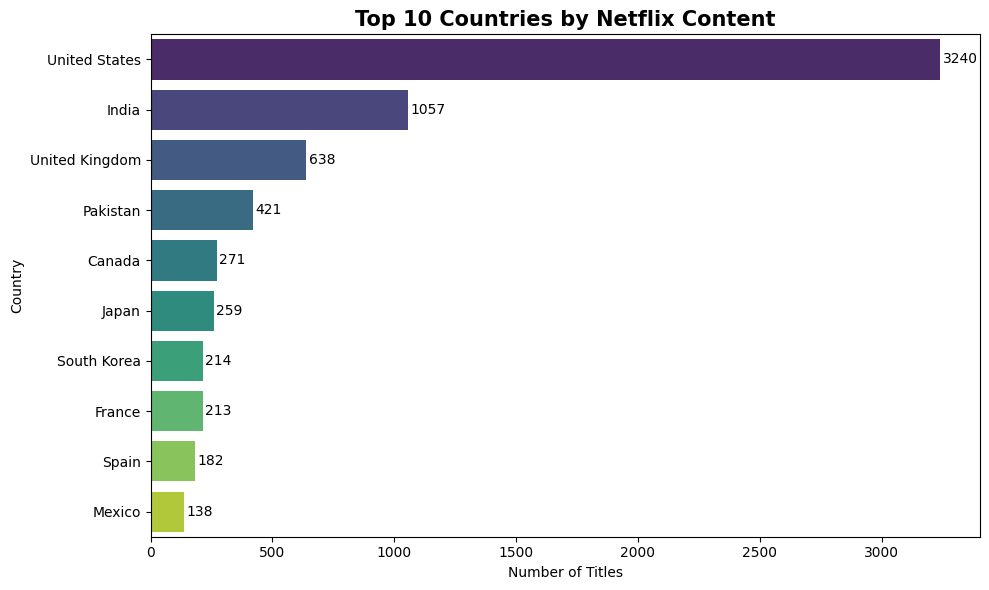

In [22]:

# STEP 4: COUNTRY-WISE BAR CHART

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index,
    hue=top_10_countries.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Countries by Netflix Content',
          fontsize=15, fontweight='bold')

plt.xlabel('Number of Titles')
plt.ylabel('Country')

for i, value in enumerate(top_10_countries.values):
    plt.text(value + 10, i, str(value), va='center')

plt.tight_layout()

plt.savefig('Netflix_Country_Analysis.png',
            dpi=300, bbox_inches='tight')

plt.show()


In [23]:

# STEP 5: BUSINESS INSIGHTS

print("COUNTRY-WISE NETFLIX ANALYSIS")
print("=============================")

print("1. United States ranks first with",
      country_counts.iloc[0], "titles.")

print("2. India ranks second with",
      country_counts.iloc[1], "titles.")

print("3. United States has the highest content representation.")

print("4. Netflix content is distributed across",
      len(country_counts), "countries.")

print("\nCONCLUSION:")
print("The United States contributes the highest number")
print("of Netflix country entries, followed by India")
print("and the United Kingdom.")

print("\nTASK 3 COMPLETED SUCCESSFULLY!")


COUNTRY-WISE NETFLIX ANALYSIS
1. United States ranks first with 3240 titles.
2. India ranks second with 1057 titles.
3. United States has the highest content representation.
4. Netflix content is distributed across 85 countries.

CONCLUSION:
The United States contributes the highest number
of Netflix country entries, followed by India
and the United Kingdom.

TASK 3 COMPLETED SUCCESSFULLY!


In [24]:

# TASK 4: TREND ANALYSIS BY RELEASE YEAR

# Organize content by release year

year_data = df['release_year'].dropna()

# Convert release year into integer
year_data = year_data.astype(int)

# Display first 10 release years
print("RELEASE YEAR DATA")
print("-----------------")
print(year_data.head(10))

print("\nTotal Records:", len(year_data))

print("Earliest Release Year:", year_data.min())
print("Latest Release Year:", year_data.max())


RELEASE YEAR DATA
-----------------
0    2020
1    2021
2    2021
3    2021
4    1993
5    2021
6    2021
7    2019
8    2021
9    2013
Name: release_year, dtype: int64

Total Records: 8790
Earliest Release Year: 1925
Latest Release Year: 2021


In [25]:
yearly_counts = df.groupby('release_year').size().sort_index()

print("YEAR-WISE NETFLIX CONTENT COUNT")
print("--------------------------------")
print(yearly_counts.tail(20))

YEAR-WISE NETFLIX CONTENT COUNT
--------------------------------
release_year
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
dtype: int64


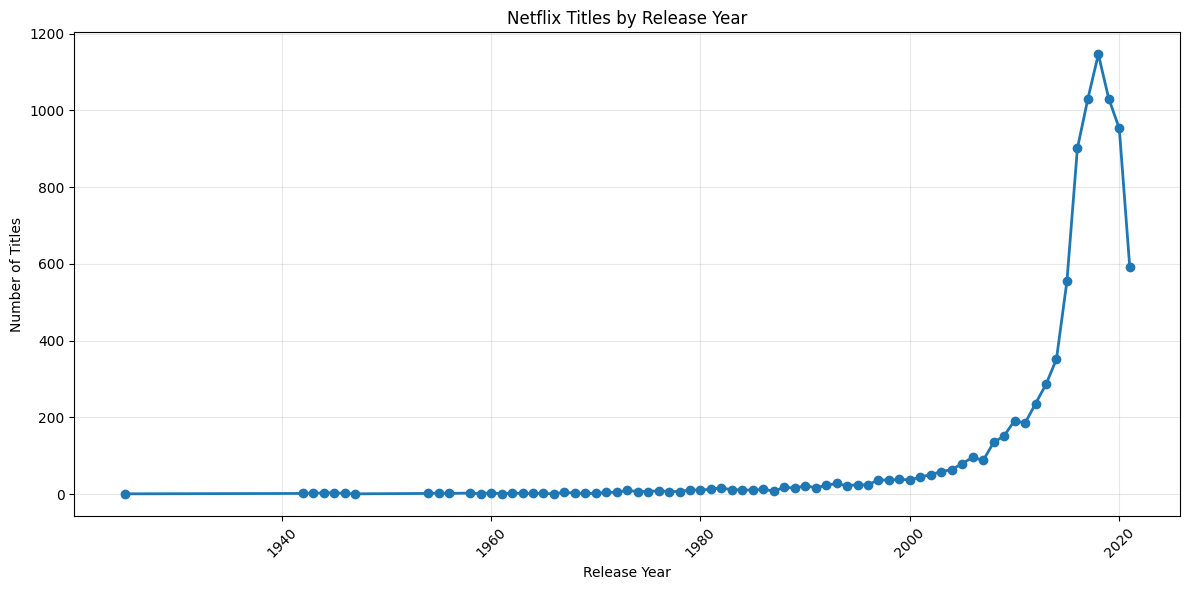

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts.index,
    yearly_counts.values,
    marker='o',
    linewidth=2
)

plt.title('Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    'Netflix_Release_Year_Trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [27]:
peak_year = yearly_counts.idxmax()
peak_count = yearly_counts.max()

print("RELEASE YEAR TREND ANALYSIS")
print("---------------------------")
print("Total Titles Analysed:", yearly_counts.sum())
print("Peak Release Year:", peak_year)
print("Highest Number of Titles:", peak_count)

print("\nKEY BUSINESS INSIGHTS")
print("1. Netflix content shows an overall increase in releases over the years.")
print(f"2. The highest number of titles were released in {peak_year}.")
print(f"3. A total of {peak_count} titles belong to {peak_year}.")
print("4. The title count decreased from 2019 to 2021.")

print("\nCONCLUSION:")
print("The analysis shows an increase in Netflix titles over time,")
print("with the highest count in 2018, followed by a decline in recent years.")

RELEASE YEAR TREND ANALYSIS
---------------------------
Total Titles Analysed: 8790
Peak Release Year: 2018
Highest Number of Titles: 1146

KEY BUSINESS INSIGHTS
1. Netflix content shows an overall increase in releases over the years.
2. The highest number of titles were released in 2018.
3. A total of 1146 titles belong to 2018.
4. The title count decreased from 2019 to 2021.

CONCLUSION:
The analysis shows an increase in Netflix titles over time,
with the highest count in 2018, followed by a decline in recent years.


In [28]:
yearly_summary = yearly_counts.reset_index()

yearly_summary.columns = [
    'Release Year',
    'Number of Titles'
]

yearly_summary.to_csv(
    'Netflix_Yearly_Trend_Summary.csv',
    index=False
)

print("Task 4 summary exported successfully!")


Task 4 summary exported successfully!


In [29]:
import os

print(os.listdir('/content'))

['.config', 'Dataset.csv', 'Netflix_Pie_Chart.png', 'Netflix_Bar_Chart.png', 'Netflix_Country_Analysis.png', 'Dataset (1).csv', 'Netflix_Cleaned_Data.csv', 'Netflix_Release_Year_Trend.png', 'Netflix_Yearly_Trend_Summary.csv', 'sample_data']


In [30]:
import os

print(os.listdir('/content'))

['.config', 'Dataset.csv', 'Netflix_Pie_Chart.png', 'Netflix_Bar_Chart.png', 'Netflix_Country_Analysis.png', 'Dataset (1).csv', 'Netflix_Cleaned_Data.csv', 'Netflix_Release_Year_Trend.png', 'Netflix_Yearly_Trend_Summary.csv', 'sample_data']


In [31]:
import pandas as pd

df = pd.read_csv('/content/Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Dataset Shape: (8790, 10)
  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, Inte

In [32]:
import os
import zipfile

files_to_save = [
    'Netflix_Cleaned_Data.csv',
    'Netflix_Bar_Chart.png',
    'Netflix_Pie_Chart.png',
    'Netflix_Country_Analysis.png',
    'Netflix_Release_Year_Trend.png',
    'Netflix_Yearly_Trend_Summary.csv'
]

with zipfile.ZipFile('Netflix_Project_Files.zip', 'w') as zipf:
    for filename in files_to_save:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

from google.colab import files
files.download('Netflix_Project_Files.zip')

Added: Netflix_Cleaned_Data.csv
Added: Netflix_Bar_Chart.png
Added: Netflix_Pie_Chart.png
Added: Netflix_Country_Analysis.png
Added: Netflix_Release_Year_Trend.png
Added: Netflix_Yearly_Trend_Summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>